# 04 Auswertung

Dieses Notebook wertet die drei Experimente aus Notebook 03 aus. Es liest ausschließlich die CSV-Dateien in `results/<experiment>/runs/` und trainiert nichts. Die Abbildungen werden zusätzlich als PNG in `figures/` gespeichert.

Ausgewertet werden nur Seeds, für die alle fünf Varianten fertig sind (`load_complete` in `analysis.py`). So bleiben alle Vergleiche gepaart: Jede Differenz wird zwischen zwei Läufen mit identischen Startgewichten gebildet.

## Kennzahlen

Pro Lauf berechnet `run_metrics` in `analysis.py`:

| Kennzahl | Bedeutung |
|---|---|
| `best_val_acc` | höchste Val-Accuracy über alle Epochen |
| `best_val_acc_epoch` | Epoche, in der sie erreicht wird |
| `test_acc_at_best` | Test-Accuracy in dieser Epoche (ehrliche Schätzung, weil die Epoche anhand von Val gewählt wurde) |
| `min_val_loss`, `min_val_loss_epoch` | niedrigster Val-Loss und seine Epoche |
| `gap_last_epoch` | Generalization Gap: Val-Loss − Train-Loss in der letzten Epoche |
| `acc_gap_last_epoch` | Train-Accuracy − Val-Accuracy in der letzten Epoche |
| `val_loss_at_common_train_loss` | Val-Loss in dem Moment, in dem der Train-Loss ein gemeinsames Niveau erreicht |

Zur letzten Kennzahl: Varianten, die schneller lernen, haben in derselben Epoche einen kleineren Train-Loss. Ein Gap in einer festen Epoche vergleicht deshalb Modelle mit unterschiedlichem Trainingsstand. Fairer ist es, den Val-Loss bei gleicher Anpassung an die Trainingsdaten zu vergleichen. Das gemeinsame Niveau (`common_train_loss`) ist der größte End-Train-Loss unter allen Läufen von A-D; jeder Lauf erreicht es also irgendwann. Der Val-Loss an dieser Stelle wird zwischen den zwei benachbarten Epochen interpoliert (`val_loss_at_train_loss`). E ist hier ausgenommen, weil sie dieses Niveau nicht erreicht.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from batch_shuffling_regularization.analysis import SHUFFLE_VARIANTS, VARIANT_NAMES, common_train_loss, load_complete, paired_comparison, run_metrics
from batch_shuffling_regularization.experiment import EXPERIMENTS, RESULTS_DIR

FIG_DIR = RESULTS_DIR.parent / "figures"
FIG_DIR.mkdir(exist_ok=True)

COLORS = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a", "D": "#eda100", "E": "#e87ba4"}
STYLES = {"C": "--"}
TITLES = {"mnist_bs100": "MNIST, Batchgröße 100", "mnist_bs10": "MNIST, Batchgröße 10", "fashion_bs100": "Fashion-MNIST, Batchgröße 100"}


def style_axes(ax: plt.Axes) -> None:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)


def save(fig: plt.Figure, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## Daten laden

In [2]:
results = {name: load_complete(experiment) for name, experiment in EXPERIMENTS.items()}
levels = {name: common_train_loss(df) for name, df in results.items()}
metrics = {name: run_metrics(df, levels[name]) for name, df in results.items()}

pd.DataFrame(
    {
        "ausgewertete Seeds": {name: df["seed"].nunique() for name, df in results.items()},
        "gemeinsames Train-Loss-Niveau": levels,
    }
)

,ausgewertete Seeds,gemeinsames Train-Loss-Niveau
mnist_bs100,20,0.000856
mnist_bs10,3,0.000781
fashion_bs100,20,0.149776


Falls ein Experiment noch nicht alle 20 Seeds hat, werden nur die fertigen Seeds ausgewertet. Die Aussagen für dieses Experiment sind dann entsprechend unsicherer.

## 1 Lernkurven

Train- und Val-Loss pro Epoche für A-D, Mittelwert über die Seeds, die Fläche zeigt ± eine Standardabweichung. Logarithmische y-Achse. E fehlt hier, weil ihr Loss um ein Vielfaches höher liegt; sie hat einen eigenen Abschnitt (6).

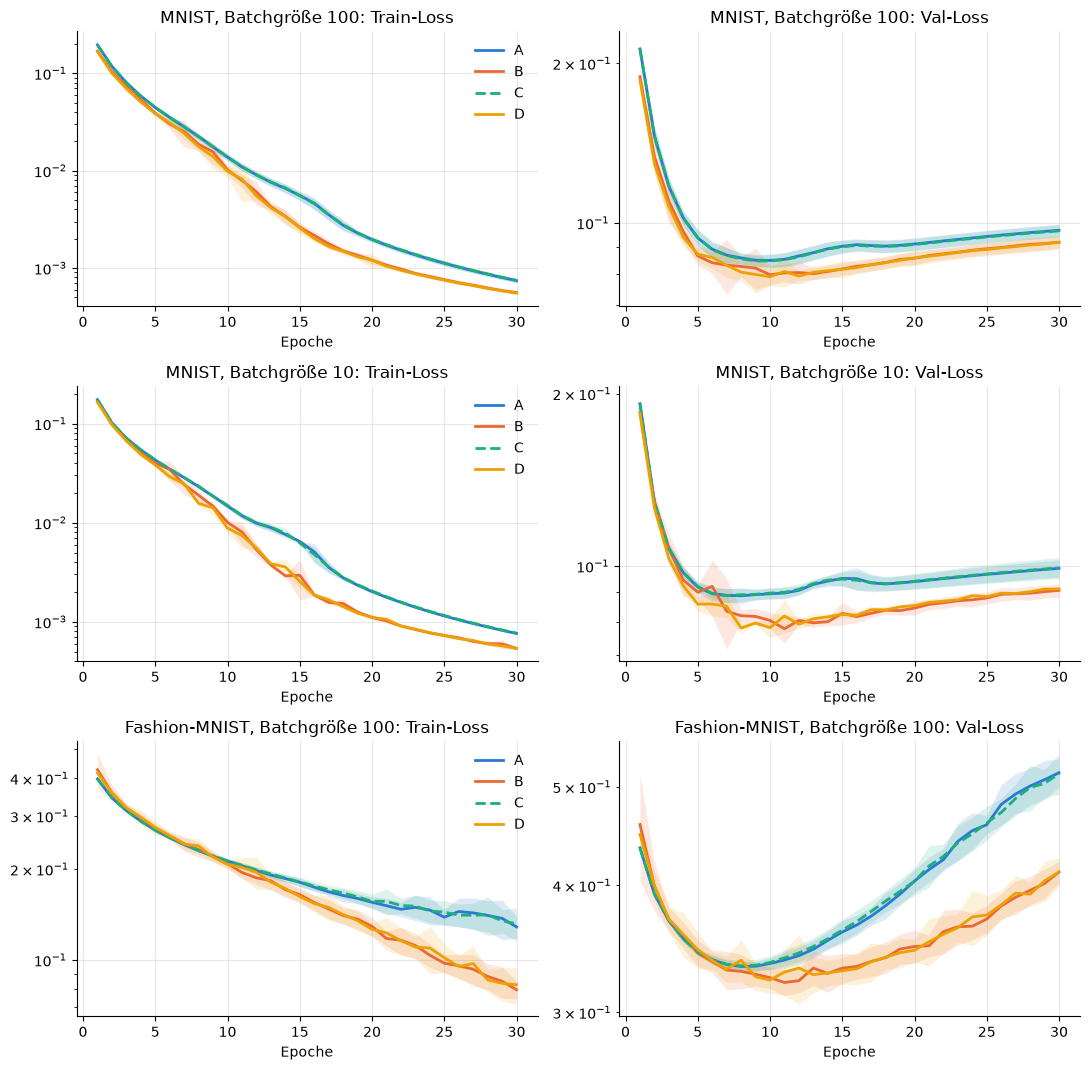

In [3]:
fig, axes = plt.subplots(len(results), 2, figsize=(11, 3.6 * len(results)), squeeze=False)
for row, (name, df) in enumerate(results.items()):
    for col, column in enumerate(["train_loss", "val_loss"]):
        ax = axes[row, col]
        for variant in SHUFFLE_VARIANTS:
            curve = df[(df["variant"] == variant) & (df["epoch"] > 0)].groupby("epoch")[column].agg(["mean", "std"])
            ax.plot(curve.index, curve["mean"], STYLES.get(variant, "-"), color=COLORS[variant], lw=2, label=variant)
            ax.fill_between(curve.index, curve["mean"] - curve["std"], curve["mean"] + curve["std"], color=COLORS[variant], alpha=0.15, lw=0)
        ax.set(yscale="log", xlabel="Epoche", title=f"{TITLES[name]}: {'Train' if column == 'train_loss' else 'Val'}-Loss")
        style_axes(ax)
    axes[row, 0].legend(frameon=False)
fig.tight_layout()
save(fig, "learning_curves")

Lesehilfe: Der Train-Loss fällt immer weiter, während der Val-Loss nach einigen Epochen sein Minimum erreicht und wieder steigt (Overfitting). Interessant ist, ob die Kurven der Varianten beim Val-Loss auseinanderlaufen und ob A und C übereinander liegen.

## 2 Generalization Gap über die Epochen

Val-Loss − Train-Loss pro Epoche, Mittelwert ± Standardabweichung über die Seeds.

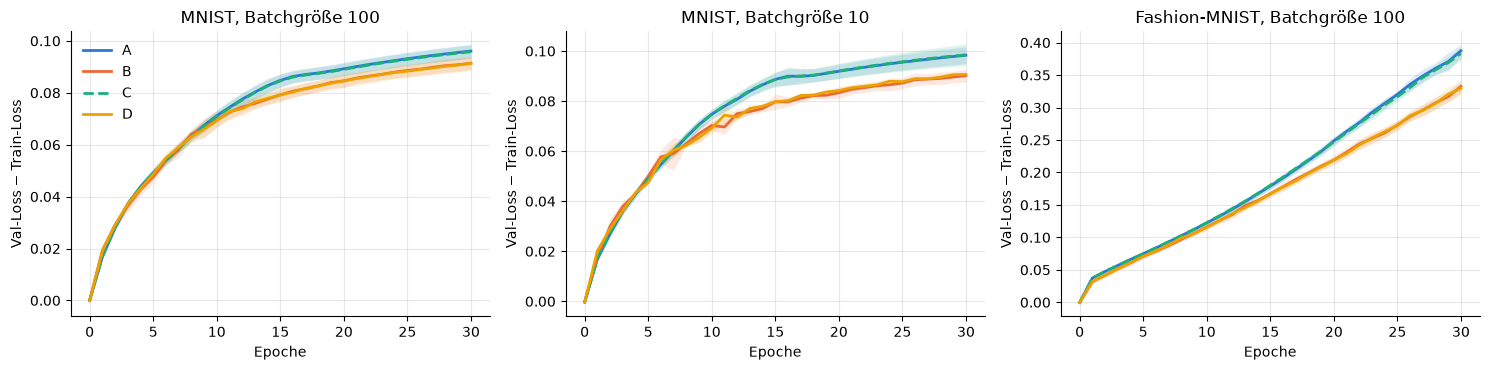

In [4]:
fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 3.8), squeeze=False)
for ax, (name, df) in zip(axes[0], results.items()):
    for variant in SHUFFLE_VARIANTS:
        curve = df[df["variant"] == variant].groupby("epoch")["gap"].agg(["mean", "std"])
        ax.plot(curve.index, curve["mean"], STYLES.get(variant, "-"), color=COLORS[variant], lw=2, label=variant)
        ax.fill_between(curve.index, curve["mean"] - curve["std"], curve["mean"] + curve["std"], color=COLORS[variant], alpha=0.15, lw=0)
    ax.set(xlabel="Epoche", ylabel="Val-Loss − Train-Loss", title=TITLES[name])
    style_axes(ax)
axes[0, 0].legend(frameon=False)
fig.tight_layout()
save(fig, "generalization_gap")

Lesehilfe: Ein kleinerer Gap heißt, dass das Modell auf ungesehenen Daten näher an seiner Leistung auf den Trainingsdaten liegt. Weil die Varianten unterschiedlich schnell lernen, vergleicht diese Abbildung in jeder Epoche aber Modelle mit unterschiedlichem Trainingsstand. Das korrigiert Abschnitt 3.

## 3 Val-Loss bei gleichem Train-Loss

Jeder Punkt einer Kurve ist eine Epoche, gemittelt über die Seeds (Train-Loss geometrisch, Val-Loss arithmetisch). Die x-Achse ist umgedreht, das Training läuft also von links nach rechts. Die gestrichelte Linie markiert das gemeinsame Train-Loss-Niveau, an dem `val_loss_at_common_train_loss` gemessen wird.

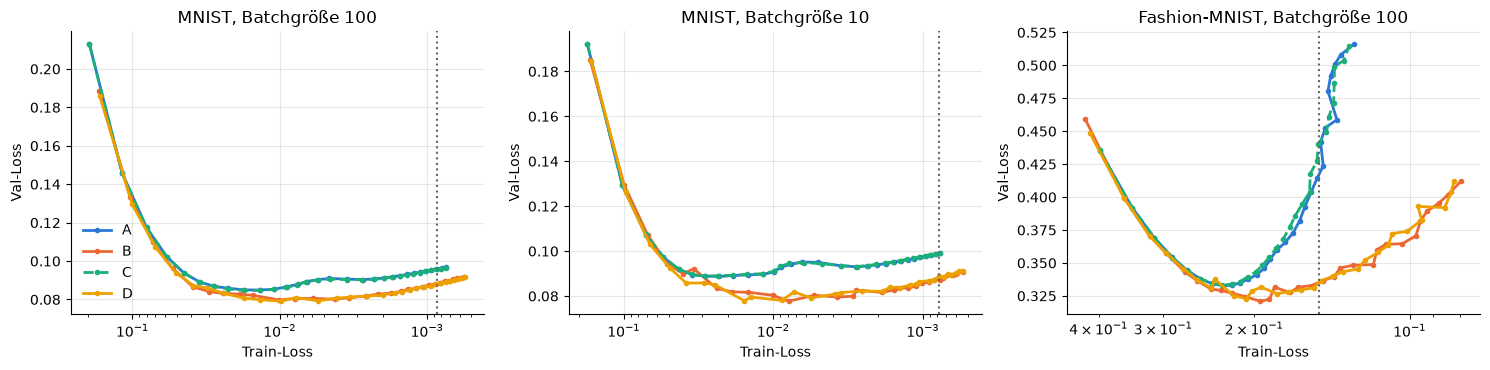

In [5]:
fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 3.8), squeeze=False)
for ax, (name, df) in zip(axes[0], results.items()):
    for variant in SHUFFLE_VARIANTS:
        sub = df[(df["variant"] == variant) & (df["epoch"] > 0)]
        curve = sub.groupby("epoch").agg(train_loss=("train_loss", lambda s: np.exp(np.log(s).mean())), val_loss=("val_loss", "mean"))
        ax.plot(curve["train_loss"], curve["val_loss"], STYLES.get(variant, "-"), color=COLORS[variant], lw=2, marker="o", ms=3, label=variant)
    ax.axvline(levels[name], color="0.4", ls=":", lw=1.5)
    ax.set(xscale="log", xlabel="Train-Loss", ylabel="Val-Loss", title=TITLES[name])
    ax.invert_xaxis()
    style_axes(ax)
axes[0, 0].legend(frameon=False)
fig.tight_layout()
save(fig, "val_vs_train_loss")

Lesehilfe: Liegt eine Kurve tiefer, hat diese Variante bei gleich guter Anpassung an die Trainingsdaten einen niedrigeren Val-Loss, sie generalisiert also besser, unabhängig davon, wie schnell sie trainiert.

## 4 Beste Val-Accuracy und Streuung über die Seeds

Jeder Punkt ist ein Seed, der schwarze Strich der Mittelwert. Die y-Achsen sind pro Experiment unterschiedlich skaliert.

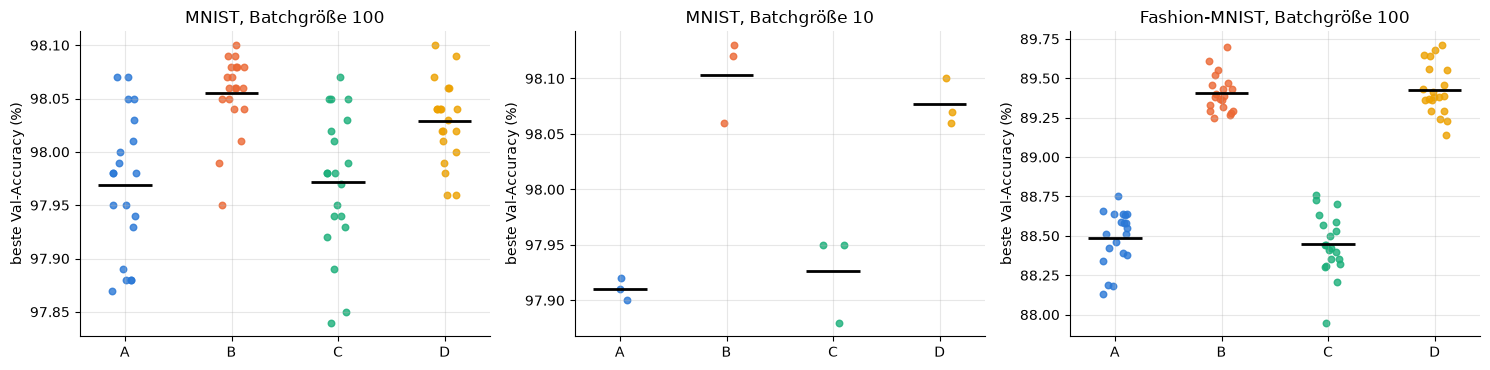

In [6]:
fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 3.8), squeeze=False)
rng = np.random.default_rng(0)
for ax, (name, m) in zip(axes[0], metrics.items()):
    for x, variant in enumerate(SHUFFLE_VARIANTS):
        values = m.loc[variant, "best_val_acc"] * 100
        ax.scatter(x + rng.uniform(-0.12, 0.12, len(values)), values, s=22, color=COLORS[variant], alpha=0.8)
        ax.hlines(values.mean(), x - 0.25, x + 0.25, color="black", lw=2)
    ax.set_xticks(range(len(SHUFFLE_VARIANTS)), SHUFFLE_VARIANTS)
    ax.set(ylabel="beste Val-Accuracy (%)", title=TITLES[name])
    style_axes(ax)
fig.tight_layout()
save(fig, "best_val_acc")

Übersicht aller Kennzahlen pro Variante, Mittelwert ± Standardabweichung über die Seeds (Accuracies in %):

In [7]:
ACC_COLUMNS = ["best_val_acc", "test_acc_at_best", "acc_gap_last_epoch"]
EPOCH_COLUMNS = ["best_val_acc_epoch", "min_val_loss_epoch"]


def summary_table(m: pd.DataFrame) -> pd.DataFrame:
    scaled = m.copy()
    scaled[ACC_COLUMNS] *= 100
    grouped = scaled.groupby("variant")
    mean, std = grouped.mean(), grouped.std()
    digits = {column: 2 if column in ACC_COLUMNS else 1 if column in EPOCH_COLUMNS else 4 for column in m.columns}
    return pd.DataFrame(
        {column: [f"{mean.loc[v, column]:.{digits[column]}f} ± {std.loc[v, column]:.{digits[column]}f}" if pd.notna(mean.loc[v, column]) else "" for v in VARIANT_NAMES] for column in m.columns},
        index=pd.Index(VARIANT_NAMES, name="Variante"),
    )


for name, m in metrics.items():
    print(TITLES[name])
    display(summary_table(m))

MNIST, Batchgröße 100


,best_val_acc,best_val_acc_epoch,test_acc_at_best,min_val_loss,min_val_loss_epoch,gap_last_epoch,acc_gap_last_epoch,val_loss_at_common_train_loss
Variante,,,,,,,,
A,97.97 ± 0.07,24.9 ± 4.6,98.02 ± 0.08,0.0845 ± 0.0022,9.7 ± 0.9,0.0961 ± 0.0026,2.05 ± 0.07,0.0959 ± 0.0025
B,98.06 ± 0.04,21.2 ± 4.9,98.12 ± 0.05,0.0771 ± 0.0025,9.7 ± 2.1,0.0914 ± 0.0024,1.99 ± 0.05,0.0883 ± 0.0020
C,97.97 ± 0.07,24.6 ± 4.3,98.02 ± 0.08,0.0844 ± 0.0022,9.8 ± 1.1,0.0958 ± 0.0026,2.05 ± 0.07,0.0957 ± 0.0026
D,98.03 ± 0.04,20.1 ± 5.1,98.08 ± 0.07,0.0768 ± 0.0016,9.8 ± 1.6,0.0913 ± 0.0025,2.01 ± 0.05,0.0880 ± 0.0024
E,55.73 ± 2.87,30.0 ± 0.0,56.13 ± 2.77,2.2539 ± 0.0844,13.4 ± 15.3,0.0705 ± 0.0161,0.79 ± 0.20,


MNIST, Batchgröße 10


,best_val_acc,best_val_acc_epoch,test_acc_at_best,min_val_loss,min_val_loss_epoch,gap_last_epoch,acc_gap_last_epoch,val_loss_at_common_train_loss
Variante,,,,,,,,
A,97.91 ± 0.01,25.3 ± 4.5,98.07 ± 0.06,0.0885 ± 0.0025,8.3 ± 0.6,0.0983 ± 0.0034,2.10 ± 0.01,0.0990 ± 0.0035
B,98.10 ± 0.04,26.3 ± 5.5,98.07 ± 0.03,0.0761 ± 0.0027,10.3 ± 3.1,0.0901 ± 0.0025,1.93 ± 0.05,0.0872 ± 0.0023
C,97.93 ± 0.04,24.0 ± 6.9,98.04 ± 0.07,0.0887 ± 0.0025,8.0 ± 1.0,0.0985 ± 0.0042,2.09 ± 0.05,0.0991 ± 0.0042
D,98.08 ± 0.02,23.3 ± 4.9,98.11 ± 0.05,0.0757 ± 0.0011,9.7 ± 1.5,0.0907 ± 0.0003,1.99 ± 0.04,0.0885 ± 0.0004
E,40.09 ± 3.28,30.0 ± 0.0,41.07 ± 2.95,2.3116 ± 0.0022,0.0 ± 0.0,0.0777 ± 0.0190,1.13 ± 0.42,


Fashion-MNIST, Batchgröße 100


,best_val_acc,best_val_acc_epoch,test_acc_at_best,min_val_loss,min_val_loss_epoch,gap_last_epoch,acc_gap_last_epoch,val_loss_at_common_train_loss
Variante,,,,,,,,
A,88.49 ± 0.17,20.7 ± 7.9,88.14 ± 0.18,0.3322 ± 0.0034,8.2 ± 0.8,0.3874 ± 0.0099,7.02 ± 0.27,0.4200 ± 0.0321
B,89.40 ± 0.12,21.2 ± 4.4,89.01 ± 0.24,0.3131 ± 0.0049,12.0 ± 1.7,0.3326 ± 0.0108,8.11 ± 0.25,0.3343 ± 0.0110
C,88.45 ± 0.19,19.7 ± 7.3,88.13 ± 0.26,0.3327 ± 0.0041,8.4 ± 1.0,0.3833 ± 0.0100,7.01 ± 0.26,0.4301 ± 0.0406
D,89.43 ± 0.16,22.9 ± 5.1,89.05 ± 0.23,0.3131 ± 0.0038,11.4 ± 1.7,0.3297 ± 0.0087,8.05 ± 0.28,0.3334 ± 0.0113
E,39.15 ± 2.30,27.0 ± 2.2,38.63 ± 2.38,2.2831 ± 0.0528,4.7 ± 9.7,0.0151 ± 0.0170,-0.38 ± 0.18,


## 5 Gepaarte Vergleiche

Für jedes Paar von Varianten wird pro Seed die Differenz gebildet (gleiche Startgewichte) und dann über die Seeds gemittelt (`paired_comparison` in `analysis.py`). Angegeben sind:

- **Differenz**: Mittelwert der Differenzen, mit 95 %-Konfidenzintervall (t-Verteilung).
- **Seeds mit Differenz > 0**: in wie vielen Seeds die erste Variante den höheren Wert hat.
- **p (Wilcoxon)**: Wilcoxon-Vorzeichen-Rang-Test, prüft, ob die Differenzen systematisch von 0 abweichen, ohne Normalverteilung vorauszusetzen.

Beim Lesen der p-Werte beachten: Hier werden viele Vergleiche gleichzeitig gerechnet. Ein einzelnes p um 0,03 ist bei so vielen Tests auch durch Zufall zu erwarten. Belastbar sind Effekte, die über mehrere Kennzahlen hinweg konsistent auftreten.

Die Vergleiche:
- **B − A** und **D − A**: bringt Shuffling überhaupt etwas?
- **D − B**: bringen neue Batch-Zusammensetzungen etwas über das Mischen der Reihenfolge hinaus?
- **C − A**: Kontrolle, sollte ≈ 0 sein.

In [8]:
PAIRS = [("B", "A"), ("D", "A"), ("D", "B"), ("C", "A")]
COMPARED = ["best_val_acc", "test_acc_at_best", "min_val_loss", "val_loss_at_common_train_loss", "gap_last_epoch"]
comparisons = {name: paired_comparison(m, PAIRS, COMPARED) for name, m in metrics.items()}

for name, table in comparisons.items():
    print(TITLES[name])
    display(table.style.format({"Differenz": "{:+.5f}", "95%-KI unten": "{:+.5f}", "95%-KI oben": "{:+.5f}", "p (Wilcoxon)": "{:.4f}"}))

MNIST, Batchgröße 100


MNIST, Batchgröße 10


Fashion-MNIST, Batchgröße 100


Die wichtigsten Vergleiche als Abbildung: Punkt = mittlere Differenz, Balken = 95 %-Konfidenzintervall. Ein Balken, der die Nulllinie nicht schneidet, ist ein systematischer Unterschied. Bei der Accuracy bedeutet rechts von 0 "erste Variante besser", beim Val-Loss links von 0.

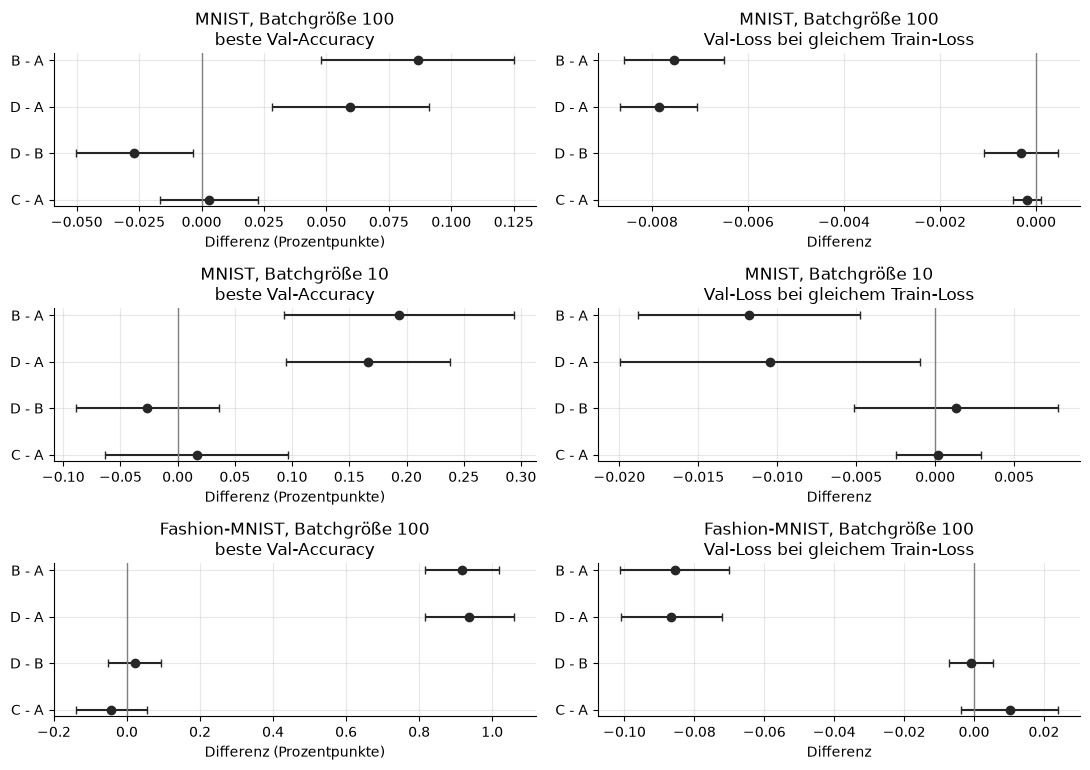

In [9]:
FOREST_METRICS = {"best_val_acc": ("beste Val-Accuracy", 100, "Differenz (Prozentpunkte)"), "val_loss_at_common_train_loss": ("Val-Loss bei gleichem Train-Loss", 1, "Differenz")}

fig, axes = plt.subplots(len(comparisons), len(FOREST_METRICS), figsize=(11, 2.6 * len(comparisons)), squeeze=False)
for row, (name, table) in enumerate(comparisons.items()):
    for col, (metric, (label, scale, xlabel)) in enumerate(FOREST_METRICS.items()):
        ax = axes[row, col]
        sub = table.xs(metric, level="Kennzahl").iloc[::-1]
        y = np.arange(len(sub))
        ax.errorbar(sub["Differenz"] * scale, y, xerr=[(sub["Differenz"] - sub["95%-KI unten"]) * scale, (sub["95%-KI oben"] - sub["Differenz"]) * scale],
                    fmt="o", color="0.15", ecolor="0.15", capsize=3, ms=6)
        ax.axvline(0, color="0.5", lw=1)
        ax.set_yticks(y, sub.index)
        ax.set(xlabel=xlabel, title=f"{TITLES[name]}\n{label}")
        style_axes(ax)
fig.tight_layout()
save(fig, "paired_differences")

## 6 Variante E: nach Klasse sortiert

Val-Accuracy pro Epoche für A (Referenz) und E, Mittelwert ± Standardabweichung über die Seeds.

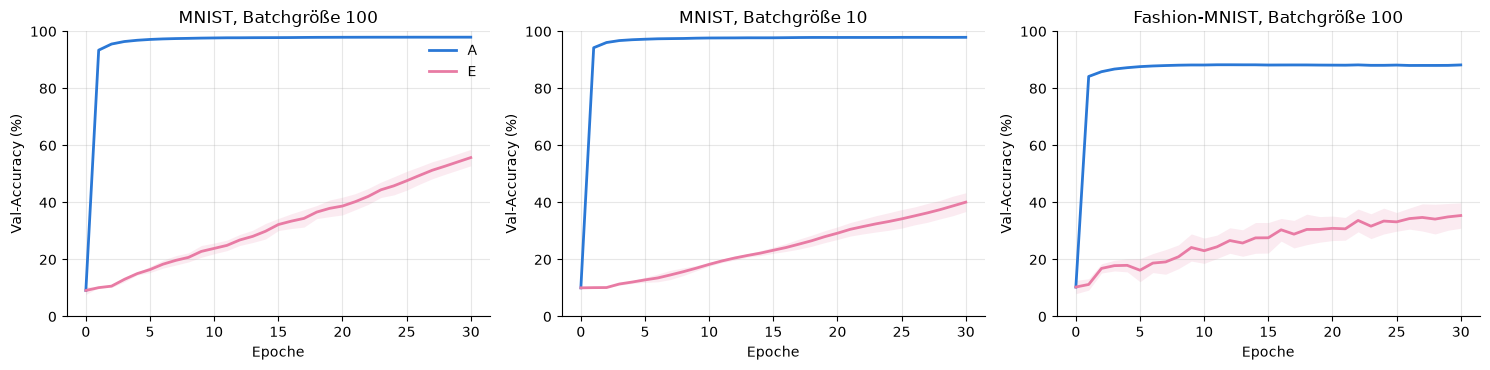

In [10]:
fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 3.8), squeeze=False)
for ax, (name, df) in zip(axes[0], results.items()):
    for variant in ["A", "E"]:
        curve = df[df["variant"] == variant].groupby("epoch")["val_acc"].agg(["mean", "std"]) * 100
        ax.plot(curve.index, curve["mean"], color=COLORS[variant], lw=2, label=variant)
        ax.fill_between(curve.index, curve["mean"] - curve["std"], curve["mean"] + curve["std"], color=COLORS[variant], alpha=0.15, lw=0)
    ax.set(xlabel="Epoche", ylabel="Val-Accuracy (%)", ylim=(0, 100), title=TITLES[name])
    style_axes(ax)
axes[0, 0].legend(frameon=False)
fig.tight_layout()
save(fig, "variant_e")

Lesehilfe: Gemessen wird immer am Ende einer Epoche. Bei E hat das Modell da zuletzt 50 Schritte lang nur die letzte Klasse gesehen und sagt überwiegend diese voraus.